# 🧠 (Problem 4) Traveling Salesman Problem — Hopfield Neural Network
### Interactive Classroom Demo

Run the final cell and watch the network solve the TSP live — no widgets needed.

| Panel | What it shows |
|-------|---------------|
| 🗺️ **Route Map** | The inferred tour evolving on a geographic map |
| 🔥 **V Matrix** | Neuron activations sharpening toward a valid permutation |
| ⚡ **Energy Curve** | Network energy dropping as it converges |

In [20]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import clear_output
import time
import warnings
warnings.filterwarnings('ignore')

print('Libraries loaded ✓')

Libraries loaded ✓


## City Setup & Distance Matrix

In [21]:
cities = ['San Diego', 'Los Angeles', 'Chicago', 'New York', 'Boston', 'Seattle']
N = len(cities)

coords = np.array([
    [-117.2, 32.7],
    [-118.2, 34.1],
    [ -87.6, 41.9],
    [ -74.0, 40.7],
    [ -71.1, 42.4],
    [-122.3, 47.6],
])

D_raw = np.zeros((N, N))
for i in range(N):
    for j in range(N):
        D_raw[i, j] = np.sqrt(np.sum((coords[i] - coords[j])**2))
D_norm = D_raw / D_raw.max()

CITY_COLORS = [
    '#FF6B6B', # San Diego
    '#4ECDC4', # Los Angeles
    '#45B7D1', # Chicago
    '#96CEB4', # New York
    '#FFEAA7', # Boston
    '#FF6B6B', # Seattle
]

BG     = '#1a1a2e'
PANEL  = '#16213e'
LBLUE  = '#4ECDC4'
GREEN  = '#0ead69'
YELLOW = '#f5a623'
ACCENT = '#e94560'

VMAP = LinearSegmentedColormap.from_list(
    'vmap', ['#1a1a2e', '#e94560', '#f5a623', '#ffffff'], N=256
)

print('Cities configured ✓')

Cities configured ✓


## Hopfield Network

In [22]:
class HopfieldTSP:
    def __init__(self, N, D, A=500, B=500, C=200, D_coeff=100, dt=1e-4, gain=50):
        self.N, self.D = N, D
        self.A, self.B, self.C, self.D_coeff = A, B, C, D_coeff
        self.dt, self.gain = dt, gain
        self.U = 0.02 * np.random.randn(N, N)
        self.V = self._sig(self.U)

    def _sig(self, u):
        return 0.5 * (1 + np.tanh(u * self.gain / 2))

    def step(self):
        V, N = self.V, self.N
        dU = np.zeros((N, N))
        total = np.sum(V)
        for i in range(N):
            for j in range(N):
                jn, jp = (j+1)%N, (j-1)%N
                dU[i,j] = (
                    - self.A * (np.sum(V[i,:]) - V[i,j])
                    - self.B * (np.sum(V[:,j]) - V[i,j])
                    - self.C * (total - N)
                    - self.D_coeff * np.dot(self.D[i,:], V[:,jn] + V[:,jp])
                )
        self.U += self.dt * (-self.U + dU)
        self.V = self._sig(self.U)

    def energy(self):
        V, N = self.V, self.N
        E  = self.A/2 * sum((np.sum(V[i,:])**2 - np.sum(V[i,:]**2)) for i in range(N))
        E += self.B/2 * sum((np.sum(V[:,j])**2 - np.sum(V[:,j]**2)) for j in range(N))
        E += self.C/2 * (np.sum(V) - N)**2
        d  = sum(self.D[i,:] @ V[:,(j+1)%N] * V[i,j] for i in range(N) for j in range(N))
        E += self.D_coeff/2 * d
        return E

    def decode_tour(self):
        t = np.argmax(self.V, axis=0).tolist()
        return t if len(set(t)) == self.N else None

print('HopfieldTSP defined ✓')

HopfieldTSP defined ✓


## ▶ Run This Cell to Watch the Network Converge Live

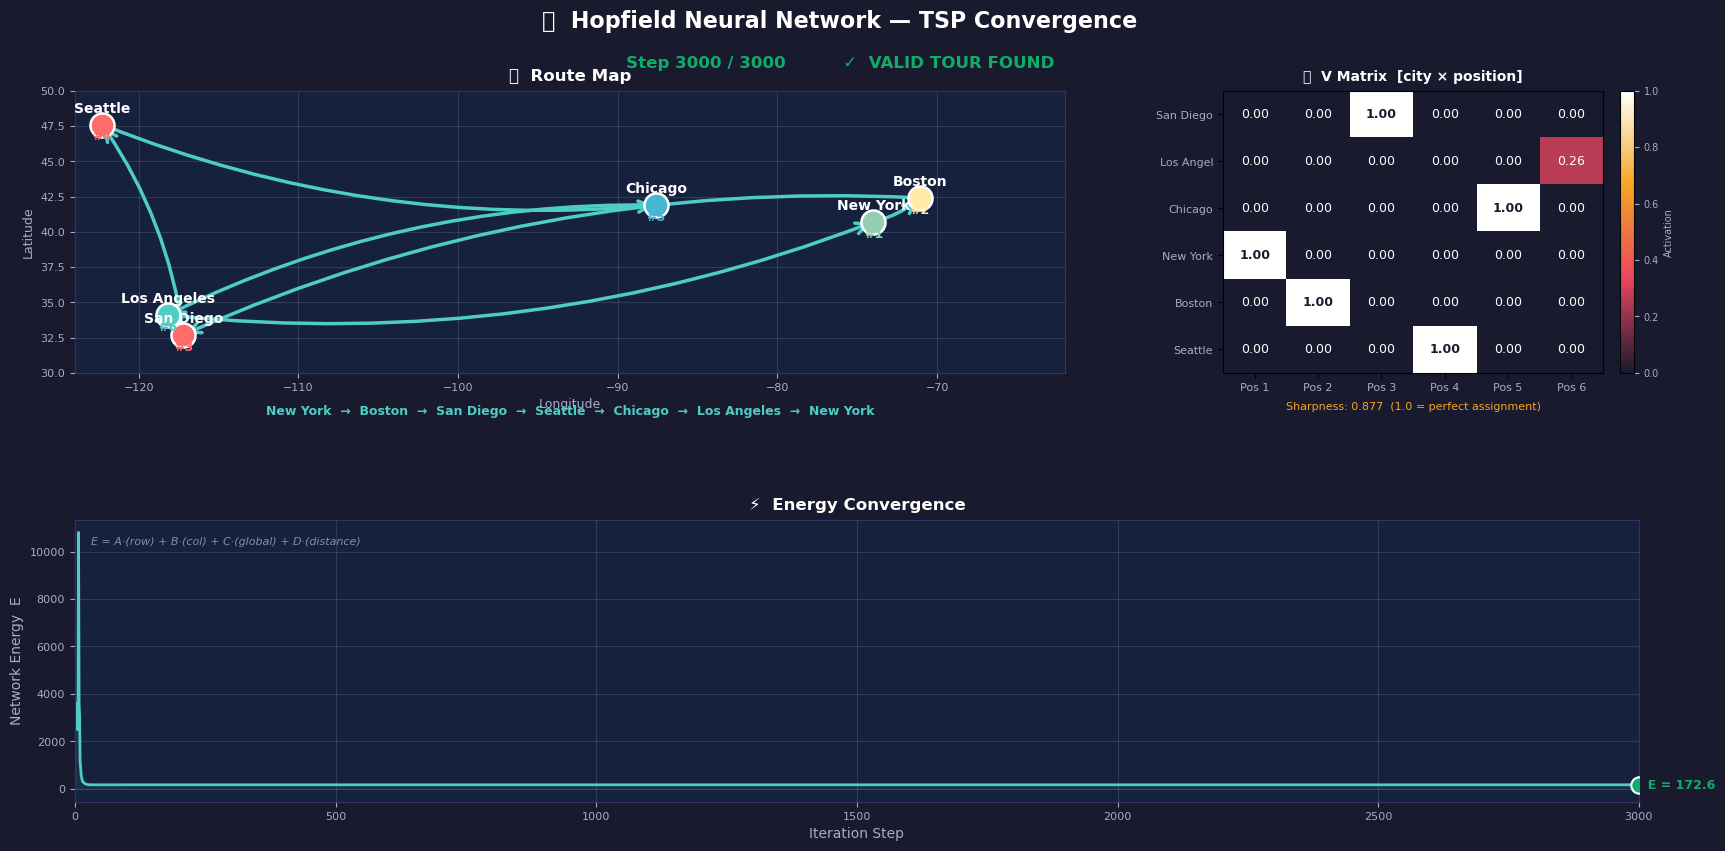


✅ Done! Scroll up to review all convergence frames.


In [29]:
# ── Settings ──────────────────────────────────────────────────────────
N_STEPS      = 3000   # total network iterations
DISPLAY_EVERY = 150   # show a frame every N steps  ← adjust for speed
FRAME_DELAY  = 0.1    # seconds between frames      ← adjust for speed

# ── Find a seed that produces a valid tour ────────────────────────────
# print('Searching for a good random seed...')
# good_seed = 0
# for seed in np.random.randint(0, 1000000, 100):
#     np.random.seed(seed)
#     test = HopfieldTSP(N, D_norm)
#     for _ in range(N_STEPS):
#         test.step()
#     if test.decode_tour() is not None:
#         good_seed = seed
#         print(f'Seed {seed} gives a valid tour ✓')
#         break

# ── Main run with live plotting ───────────────────────────────────────
good_seed = 80163
np.random.seed(good_seed)
net = HopfieldTSP(N, D_norm)

energy_history = []
step_history   = []
frame_num      = 0

display_steps = list(range(1, DISPLAY_EVERY, 10))          # a few early frames
display_steps += list(range(DISPLAY_EVERY, N_STEPS+1, DISPLAY_EVERY))
display_steps = sorted(set(display_steps))

for s in range(1, N_STEPS + 1):
    net.step()
    e = net.energy()
    energy_history.append(e)
    step_history.append(s)

    if s not in display_steps:
        continue

    frame_num += 1
    tour  = net.decode_tour()
    V     = net.V
    valid = tour is not None
    status_color = GREEN  if valid else YELLOW
    status_text  = '✓  VALID TOUR FOUND' if valid else '⟳  Converging…'
    sharpness = (np.mean(np.max(V, axis=1)) + np.mean(np.max(V, axis=0))) / 2

    # ── Build figure ──────────────────────────────────────────────────
    fig = plt.figure(figsize=(17, 9), facecolor=BG)
    gs  = gridspec.GridSpec(
        2, 3, figure=fig,
        left=0.05, right=0.97, top=0.88, bottom=0.09,
        wspace=0.38, hspace=0.52
    )

    # Title
    fig.text(0.5, 0.95,
             '🧠  Hopfield Neural Network — TSP Convergence',
             ha='center', fontsize=16, fontweight='bold', color='white')
    fig.text(0.5, 0.906,
             f'Step {s:>4d} / {N_STEPS}          {status_text}',
             ha='center', fontsize=12, color=status_color, fontweight='bold')

    # ── Panel A: Route Map ────────────────────────────────────────────
    ax_map = fig.add_subplot(gs[0, :2])
    ax_map.set_facecolor(PANEL)
    for sp in ax_map.spines.values(): sp.set_edgecolor('#333366')

    x, y = coords[:,0], coords[:,1]

    if valid:
        for i in range(N):
            c1, c2 = tour[i], tour[(i+1)%N]
            ax_map.annotate('',
                xy=(x[c2], y[c2]), xytext=(x[c1], y[c1]),
                arrowprops=dict(arrowstyle='->', color=LBLUE, lw=2.5,
                                connectionstyle='arc3,rad=0.12', mutation_scale=20))
    else:
        for i in range(N):
            for j in range(N):
                for k in range(N):
                    w = V[i,j] * V[k,(j+1)%N]
                    if w > 0.06:
                        ax_map.plot([x[i], x[k]], [y[i], y[k]],
                                   color=LBLUE, alpha=min(w*1.5, 0.5), lw=1.5)

    for i in range(N):
        ax_map.scatter(x[i], y[i], s=300, color=CITY_COLORS[i],
                      zorder=6, edgecolors='white', linewidths=1.8)
        ax_map.text(x[i], y[i]+0.85, cities[i],
                   ha='center', fontsize=10, fontweight='bold', color='white', zorder=7)
        if valid and i in tour:
            ax_map.text(x[i], y[i]-1.1, f'#{tour.index(i)+1}',
                       ha='center', fontsize=9, color=CITY_COLORS[i],
                       fontweight='bold', zorder=7)

    ax_map.set_xlim(-124, -62)
    ax_map.set_ylim(30, 50)
    ax_map.set_title('🗺️  Route Map', fontsize=12, fontweight='bold', color='white', pad=7)
    ax_map.set_xlabel('Longitude', fontsize=9, color='#aaaacc')
    ax_map.set_ylabel('Latitude',  fontsize=9, color='#aaaacc')
    ax_map.grid(True, alpha=0.12, color='white')
    ax_map.tick_params(colors='#aaaacc', labelsize=8)

    if valid:
        seq = '  →  '.join(cities[c] for c in tour) + f'  →  {cities[tour[0]]}'
        ax_map.text(0.5, -0.15, seq, transform=ax_map.transAxes,
                   ha='center', fontsize=9, color=LBLUE, fontweight='bold')
    else:
        ax_map.text(0.5, -0.15, 'Route undetermined — neurons still competing',
                   transform=ax_map.transAxes,
                   ha='center', fontsize=9, color=YELLOW, style='italic')

    # ── Panel B: V Matrix ─────────────────────────────────────────────
    ax_v = fig.add_subplot(gs[0, 2])
    ax_v.set_facecolor(PANEL)

    im = ax_v.imshow(V, cmap=VMAP, vmin=0, vmax=1, aspect='auto')
    for i in range(N):
        for j in range(N):
            val = V[i, j]
            ax_v.text(j, i, f'{val:.2f}',
                     ha='center', va='center', fontsize=9,
                     color='white' if val < 0.6 else '#1a1a2e',
                     fontweight='bold' if val > 0.7 else 'normal')

    ax_v.set_xticks(range(N))
    ax_v.set_xticklabels([f'Pos {k+1}' for k in range(N)], fontsize=8, color='#aaaacc')
    ax_v.set_yticks(range(N))
    ax_v.set_yticklabels([c[:9] for c in cities], fontsize=8, color='#aaaacc')
    ax_v.set_title('🔥  V Matrix  [city × position]',
                  fontsize=10, fontweight='bold', color='white', pad=7)
    cb = plt.colorbar(im, ax=ax_v, fraction=0.046, pad=0.04)
    cb.ax.tick_params(colors='#aaaacc', labelsize=7)
    cb.set_label('Activation', color='#aaaacc', fontsize=7)

    ax_v.text(0.5, -0.13,
             f'Sharpness: {sharpness:.3f}  (1.0 = perfect assignment)',
             transform=ax_v.transAxes, ha='center', fontsize=8,
             color=GREEN if sharpness > 0.9 else YELLOW)

    # ── Panel C: Energy Curve ─────────────────────────────────────────
    ax_e = fig.add_subplot(gs[1, :])
    ax_e.set_facecolor(PANEL)
    for sp in ax_e.spines.values(): sp.set_edgecolor('#333366')

    ax_e.plot(step_history, energy_history, color=LBLUE, lw=2)
    ax_e.fill_between(step_history, energy_history, alpha=0.08, color=LBLUE)
    ax_e.scatter([s], [e], s=140, color=status_color,
                zorder=6, edgecolors='white', linewidths=1.5)
    ax_e.annotate(f'  E = {e:.1f}', (s, e),
                 fontsize=9, color=status_color, fontweight='bold', va='center')

    ax_e.set_xlim(0, N_STEPS)
    ax_e.set_xlabel('Iteration Step', fontsize=10, color='#aaaacc')
    ax_e.set_ylabel('Network Energy  E', fontsize=10, color='#aaaacc')
    ax_e.set_title('⚡  Energy Convergence',
                  fontsize=12, fontweight='bold', color='white', pad=7)
    ax_e.grid(True, alpha=0.12, color='white')
    ax_e.tick_params(colors='#aaaacc', labelsize=8)
    ax_e.text(0.01, 0.91,
             'E = A·(row) + B·(col) + C·(global) + D·(distance)',
             transform=ax_e.transAxes, fontsize=8,
             color='#8888bb', style='italic')

    clear_output(wait=True)
    plt.show()
    time.sleep(FRAME_DELAY)

print('\n✅ Done! Scroll up to review all convergence frames.')

In [30]:
net.decode_tour()

[3, 4, 0, 5, 2, 1]

---
## 📖 Teaching Notes

| Stage | V Matrix | Route Map | Energy |
|-------|----------|-----------|--------|
| **Early** | All cells ≈ equal — neurons uncertain | Soft overlapping connections | High, noisy |
| **Mid** | Some cells brightening — competition starting | Structure emerging, may have conflicts | Dropping steeply |
| **Late** | One bright cell per row & column — valid permutation | Single clean tour with stop numbers | Plateau reached |

**Adjust** `DISPLAY_EVERY` and `FRAME_DELAY` in the run cell to control the speed of the demo.